# Data Preparation — BRFSS 2012 Diabetes Dataset

**Project:** Diabetes Prediction using Machine Learning  
**Dataset:** CDC Behavioral Risk Factor Surveillance System (2012)  
**Task:** Multiclass classification

This notebook follows the preparation methodology used in the
BRFSS 2015 example, adapted to the actual BRFSS 2012 data.

## Objective

Prepare the original survey dataset for machine learning by:

1. Defining the target variable.
2. Selecting relevant predictors.
3. Identifying and removing redundant variables.
4. Decoding hidden missing values.
5. Analyzing missing data.
6. Correcting data formats.
7. Examining outliers.
8. Investigating class imbalance.
9. Studying feature relationships.
10. Encoding categorical variables.
11. Splitting the dataset and creating a preprocessing pipeline.

### Important rule: prevent data leakage

Any transformation that **learns statistics from the data**,
such as imputation, scaling, or one-hot category discovery,
must be fitted on the training set only.

Fixed transformations, such as decoding survey codes,
can be applied before the split.


## Step 0 — Setup and load

### Why?

Start from the original dataset and preserve an untouched copy.

### Diagnostic result

The BRFSS 2012 dataset contains:

- **475,687 respondents**
- **359 columns**

### Decision

Load `2012.csv` into `raw`, then work on a copy named `df`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("2012.csv")

raw = pd.read_csv(DATA_PATH, low_memory=False)
df = raw.copy()

print("Original shape:", raw.shape)
print("Working shape:", df.shape)

display(df.head())

Original shape: (475687, 359)
Working shape: (475687, 359)


,_STATE,_GEOSTR,_DENSTR2,PRECALL,REPNUM,REPDEPTH,FMONTH,IDATE,IMONTH,IDAY,IYEAR,INTVID,DISPCODE,SEQNO,_PSU,NATTMPTS,NRECSEL,NRECSTR,CTELENUM,PVTRESID,COLGHOUS,CELLFON,LADULT,NUMADULT,NUMMEN,NUMWOMEN,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,HLTHPLN1,PERSDOC2,MEDCOST,CHECKUP1,EXERANY2,CVDINFR4,CVDCRHD4,CVDSTRK3,ASTHMA3,ASTHNOW,CHCSCNCR,CHCOCNCR,CHCCOPD1,HAVARTH3,ADDEPEV2,CHCKIDNY,CHCVISN1,DIABETE3,LASTDEN3,RMVTETH3,AGE,HISPANC2,MRACE,ORACE2,VETERAN3,MARITAL,CHILDREN,EDUCA,EMPLOY,INCOME2,WEIGHT2,HEIGHT3,CTYCODE1,NUMHHOL2,NUMPHON2,CPDEMO1,CPDEMO4,RENTHOM1,SEX,PREGNANT,QLACTLM2,USEEQUIP,SMOKE100,SMOKDAY2,STOPSMK2,LASTSMK2,USENOW3,ALCDAY5,AVEDRNK2,DRNK3GE5,MAXDRNKS,FLUSHOT5,FLSHTMY2,IMFVPLAC,PNEUVAC3,FALL12MN,FALLINJ2,SEATBELT,DRNKDRI2,HADMAM,HOWLONG,PROFEXAM,LENGEXAM,HADPAP2,LASTPAP2,HADHYST2,PCPSAAD1,PCPSADI1,PCPSARE1,PSATEST1,PSATIME,PCPSARS1,BLDSTOOL,LSTBLDS3,HADSIGM3,HADSGCO1,LASTSIG3,HIVTST6,HIVTSTD3,HIVRISK3,PDIABTST,PREDIAB1,DIABAGE2,INSULIN,BLDSUGAR,FEETCHK2,DOCTDIAB,CHKHEMO3,FEETCHK,EYEEXAM,DIABEYE,DIABEDU,PAINACT2,QLMENTL2,QLSTRES2,QLHLTH2,VIDFCLT2,VIREDIF2,VIPRFVS2,VINOCRE2,VIEYEXM2,VIINSUR2,VICTRCT4,VIGLUMA2,VIMACDG2,SSBSUGR1,SSBFRUT1,SSBCALRI,NUMBURN2,QLREST2,SLEPTIME,SLEPSNOR,SLEPDAY,SLEPDRIV,FRUITJU1,FRUIT1,FVBEANS,FVGREEN,FVORANG,VEGETAB1,ASTHMAGE,ASATTACK,ASERVIST,ASDRVIST,ASRCHKUP,ASACTLIM,ASYMPTOM,ASNOSLEP,ASTHMED3,ASINHALR,WRKHCF1,DIRCONT1,DRHPAD1,HAVHPAD,SHINGLE1,TNSARCV,TNSARCNT,TNSASHT1,HPVADVC2,HPVADSHT,PCPSADEC,PCDMDECN,CNCRDIFF,CNCRAGE,CNCRTYP1,CSRVTRT1,CSRVDOC1,CSRVSUM,CSRVRTRN,CSRVINST,CSRVINSR,CSRVDEIN,CSRVCLIN,CSRVPAIN,CSRVCTL1,RRCLASS2,RRCOGNT2,RRATWRK2,RRHCARE3,RRPHYSM2,RREMTSM2,MISNERVS,MISHOPLS,MISRSTLS,MISDEPRD,MISEFFRT,MISWTLES,MISNOWRK,MISTMNT,MISTRHLP,MISPHLPF,SCNTMONY,SCNTMEAL,SCNTPAID,SCNTWRK1,SCNTLPAD,SCNTLWK1,GPWELPR3,GP3DYWTR,GP3DYFD1,GP3DYPRS,GPBATRAD,GPFLSLIT,GPEMRCM1,GPEMRIN1,GPVACPL1,GPMNDEVC,GPNOTEV1,VHCOMBAT,VHDRPTSD,VHDRTBI,VHCOUNSL,VHTAKLIF,VHSUICID,COPDTEST,COPDQOL,COPDDOC,COPDHOSP,COPDMEDS,ACEDEPRS,ACEDRINK,ACEDRUGS,ACEPRISN,ACEDIVRC,ACEPUNCH,ACEHURT,ACESWEAR,ACETOUCH,ACETTHEM,ACEHVSEX,RCSBIRTH,RCSGENDR,RCHISLAT,RCSRACE,RCSBRACE,RCSRLTN2,CASTHDX2,CASTHNO2,FLUSHCH2,RCVFVCH4,WHRTST8,HIVRDTST,EMTSUPRT,LSATISFY,CALLBACK,ADLTCHLD,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,RSPSTATE,LANDLINE,PCTCELL,QSTVER,QSTLANG,MSCODE,_STSTR,_STRWT,_RAW,_WT2,_RAWRAKE,_WT2RAKE,_REGION,_IMPAGE,_IMPRACE,_IMPNPH,O_STATE,CRACEORG,CRACEASC,_CRACE,_RAWCH,_WT2CH,CHILDAGE,_CLCPM01,_CLCPM02,_CLCPM03,_CLCPM04,_CLCPM05,_CLLCPWT,_DUALUSE,_DUALCOR,_LLCPM01,_LLCPM02,_LLCPM03,_LLCPM04,_LLCPM05,_LLCPM06,_LLCPM07,_LLCPM08,_LLCPM09,_LLCPM10,_LLCPM11,_LLCPM12,_LLCPWT,_RFHLTH,_HCVU651,_TOTINDA,_LTASTH1,_CASTHM1,_ASTHMS1,_DRDXAR1,_EXTETH2,_ALTETH2,_DENVST2,MRACEORG,MRACEASC,_PRACE,_MRACE,RACE2,_RACEG2,_RACEGR2,_RACE_G,_CNRACE,_CNRACEC,_AGEG5YR,_AGE65YR,_AGE_G,HTIN4,HTM4,WTKG3,_BMI5,_BMI5CAT,_RFBMI5,_CHLDCNT,_EDUCAG,_INCOMG,_SMOKER3,_RFSMOK3,DRNKANY5,DROCDY3_,_RFBING5,_DRNKDY4,_DRNKMO4,_RFDRHV4,_RFDRMN4,_RFDRWM4,_FLSHOT5,_PNEUMO2,_RFSEAT2,_RFSEAT3,_RFMAM2Y,_MAM502Y,_RFPAP32,_RFPSA21,_RFBLDS2,_RFSIGM2,_AIDTST3
0,1.0,7.0,1.0,1.0,20118.0,3.0,2.0,b'02162012',b'02',b'16',b'2012',b'00163',1100.0,2.012001e+09,2.012001e+09,8.0,2585.0,45328.0,1.0,1.0,NaN,1.0,NaN,2.0,1.000000e+00,1.0,3.0,77.0,88.0,88.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,2.0,1.0,2.0,2.0,1.0,3.0,1.0,1.0,64.0,2.0,b'1',NaN,1.0,1.0,2.0,5.0,7.0,6.0,190.0,600.0,1.0,1.0,1.0,1.0,888.0,1.0,1.0,NaN,2.0,2.0,2.0,NaN,NaN,NaN,3.0,888.0,NaN,NaN,NaN,2.0,NaN,NaN,1.0,88.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,NaN,NaN,2.0,NaN,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,b'',NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,1.0,1.0,2.0,1.0,

**Remark:** A respondent corresponds to a person who answered
the BRFSS health survey. Each row represents one survey record.

## Step 1 — Define the target (`DIABETE3`)

### Why?

The target determines what our machine learning model will predict.

### Original codes

| Code | Meaning | Target |
|---|---|---|
| 1 | Diabetes | 2 |
| 2 | Diabetes only during pregnancy | 0 |
| 3 | No diabetes | 0 |
| 4 | Pre-diabetes | 1 |
| 7 | Don't know | Exclude |
| 9 | Refused | Exclude |

### Diagnostic result

| Original code | Respondents |
|---|---:|
| 1 | 59,763 |
| 2 | 4,067 |
| 3 | 403,299 |
| 4 | 7,735 |
| 7 | 564 |
| 9 | 259 |

### Decision

Remove **823 respondents** with invalid targets.

The remaining dataset contains **474,864 respondents**.

We use three classes:

- **0:** No diabetes (including pregnancy-only responses)
- **1:** Pre-diabetes
- **2:** Diabetes


In [2]:
print("Original target distribution:")
display(df["DIABETE3"].value_counts(dropna=False))

before = len(df)

df = df[df["DIABETE3"].isin([1, 2, 3, 4])].copy()

df["target"] = df["DIABETE3"].map({
    3: 0,
    2: 0,
    4: 1,
    1: 2
}).astype(int)

print("Removed rows:", before - len(df))
print("New shape:", df.shape)

display(df["target"].value_counts().sort_index())

Original target distribution:


DIABETE3
3.0    403299
1.0     59763
4.0      7735
2.0      4067
7.0       564
9.0       259
Name: count, dtype: int64

Removed rows: 823
New shape: (474864, 360)


target
0    407366
1      7735
2     59763
Name: count, dtype: int64

### Result / Remark

The three target classes contain:

- **407,366:** No diabetes
- **7,735:** Pre-diabetes
- **59,763:** Diabetes

The pre-diabetes class is much smaller than the other classes.
This imbalance must be considered during modeling.

## Step 2 — Select the columns

### Why?

The original dataset contains administrative fields, optional
survey modules, and questions that can reveal the target.

These columns should not automatically be used as predictors.

### 2a — Missing values

According to the diagnostic report:

- **198 columns** have more than 50% missing values.
- **121 columns** have more than 90% missing values.

These counts refer to ordinary `NaN` values, before decoding
special BRFSS missing codes.

In [3]:
missing_original = df.isna().mean().sort_values(
    ascending=False
)

print(
    "Columns >50% missing:",
    (missing_original > 0.5).sum()
)

print(
    "Columns >90% missing:",
    (missing_original > 0.9).sum()
)

display(missing_original.head(20))

Columns >50% missing: 198
Columns >90% missing: 121


VHCOMBAT    1.000000
VHTAKLIF    1.000000
VHSUICID    1.000000
VHDRTBI     1.000000
VHCOUNSL    1.000000
LSATISFY    1.000000
EMTSUPRT    1.000000
VHDRPTSD    1.000000
DRHPAD1     1.000000
WRKHCF1     1.000000
DIRCONT1    1.000000
HAVHPAD     1.000000
COLGHOUS    0.999869
CSRVCTL1    0.999415
HIVRDTST    0.997814
ASERVIST    0.997776
ASDRVIST    0.997776
CCLGHOUS    0.997761
ASNOSLEP    0.996422
HPVADSHT    0.996243
dtype: float64

### 2b — Target leakage

Some questions are specifically asked after a respondent reports
diabetes, such as insulin use or age at diagnosis.

Using these as predictors could allow the model to infer the
answer from the questionnaire structure rather than general
health indicators.

**Decision:** Exclude diabetes-specific follow-up variables,
along with the original `DIABETE3` target column.

In [4]:
leakage_cols = [
    "DIABAGE2", "INSULIN", "BLDSUGAR",
    "FEETCHK2", "FEETCHK", "DOCTDIAB",
    "CHKHEMO3", "EYEEXAM", "DIABEYE",
    "DIABEDU", "PDIABTST", "PREDIAB1"
]

available_leakage = [
    c for c in leakage_cols if c in df.columns
]

display(
    missing_original.reindex(available_leakage)
    .to_frame("Missing fraction")
)

,Missing fraction
DIABAGE2,0.926688
INSULIN,0.926695
BLDSUGAR,0.926693
FEETCHK2,0.926693
FEETCHK,0.927112
DOCTDIAB,0.926693
CHKHEMO3,0.926693
EYEEXAM,0.926695
DIABEYE,0.926697
DIABEDU,0.926699


### 2c — Select health-related features

We select variables covering:

- General and physical health
- Chronic conditions
- Smoking and physical activity
- Healthcare access
- Demographics

Unlike the 2015 example, this dataset does not contain some
2015-specific blood pressure and cholesterol variables.

**Diagnostic result:** All 27 candidate variables below exist
in the BRFSS 2012 dataset.

In [5]:
features = [
    "_BMI5", "_BMI5CAT",
    "GENHLTH", "PHYSHLTH", "MENTHLTH",

    "CVDSTRK3", "CVDINFR4", "CVDCRHD4",
    "CHCKIDNY", "CHCCOPD1",
    "HAVARTH3", "ADDEPEV2", "ASTHMA3",

    "_SMOKER3", "SMOKE100",
    "EXERANY2", "_TOTINDA", "_RFDRHV4",

    "HLTHPLN1", "MEDCOST",

    "SEX", "_AGEG5YR",
    "EDUCA", "_EDUCAG",
    "INCOME2", "_INCOMG",
    "MARITAL"
]

unavailable = [
    c for c in features if c not in df.columns
]

assert not unavailable, f"Missing columns: {unavailable}"

df = df[features + ["target"]].copy()

print("Selected features:", len(features))
print("Dataset shape:", df.shape)

Selected features: 27
Dataset shape: (474864, 28)


## Step 4 — Hidden missing values

*This step is performed before Step 3 because special missing
codes can distort correlations.*

### Why?

BRFSS uses numerical codes for answers such as:

- Don't know
- Refused
- Missing

These values are not recognized by `isna()`.

### Important exceptions

- `PHYSHLTH = 88` means **zero days**.
- `MENTHLTH = 88` means **zero days**.
- `_AGEG5YR = 14` means missing age group.
- In age groups, `7` and `9` are valid categories.
- In income groups, some values such as `7` are valid categories.

We therefore use **column-specific mappings**.

The mappings below reproduce the diagnostic preparation.
They should be cross-checked with the official BRFSS 2012 codebook
before final scientific use.

In [6]:
special_codes = {
    "GENHLTH": [7, 9],
    "PHYSHLTH": [77, 99],
    "MENTHLTH": [77, 99],

    "CVDSTRK3": [7, 9],
    "CVDINFR4": [7, 9],
    "CVDCRHD4": [7, 9],
    "CHCKIDNY": [7, 9],
    "CHCCOPD1": [7, 9],
    "HAVARTH3": [7, 9],
    "ADDEPEV2": [7, 9],
    "ASTHMA3": [7, 9],

    "_SMOKER3": [9],
    "SMOKE100": [7, 9],
    "EXERANY2": [7, 9],
    "_TOTINDA": [9],
    "_RFDRHV4": [9],

    "HLTHPLN1": [7, 9],
    "MEDCOST": [7, 9],

    "_AGEG5YR": [14],
    "EDUCA": [9],
    "_EDUCAG": [9],
    "INCOME2": [77, 99],
    "_INCOMG": [9],
    "MARITAL": [9]
}

hidden = pd.Series({
    c: df[c].isin(codes).sum()
    for c, codes in special_codes.items()
})

print("Hidden missing values:")
display(hidden.sort_values(ascending=False))

for col, codes in special_codes.items():
    df[col] = df[col].replace(codes, np.nan)

for col in ["PHYSHLTH", "MENTHLTH"]:
    df[col] = df[col].replace(88, 0)

print("Total decoded codes:", int(hidden.sum()))

display(
    df[["PHYSHLTH", "MENTHLTH", "_AGEG5YR"]]
    .describe()
)

Hidden missing values:


_INCOMG     66481
INCOME2     65732
_RFDRHV4    18928
PHYSHLTH     9831
_SMOKER3     9591
MENTHLTH     7961
_AGEG5YR     4521
CVDCRHD4     3773
MARITAL      2531
SMOKE100     2434
HAVARTH3     2359
CHCCOPD1     2262
CVDINFR4     1947
ADDEPEV2     1923
_EDUCAG      1892
_TOTINDA     1544
GENHLTH      1539
EXERANY2     1535
HLTHPLN1     1534
EDUCA        1448
CHCKIDNY     1364
ASTHMA3      1312
MEDCOST      1270
CVDSTRK3     1170
dtype: int64

Total decoded codes: 214882


,PHYSHLTH,MENTHLTH,_AGEG5YR
count,465032.000000,466903.000000,470343.000000
mean,4.388713,3.510674,7.594169
std,8.909691,7.840068,3.422321
min,0.000000,0.000000,1.000000
25%,0.000000,0.000000,5.000000
50%,0.000000,0.000000,8.000000
75%,3.000000,2.000000,10.000000
max,30.000000,30.000000,13.000000


### Result / Remark

The diagnostic report identified:

| Variable | Hidden missing values |
|---|---:|
| `_INCOMG` | 66,481 |
| `INCOME2` | 65,732 |
| `_RFDRHV4` | 18,928 |
| `PHYSHLTH` | 9,831 |
| `_SMOKER3` | 9,591 |
| `MENTHLTH` | 7,961 |

**Decision:** Convert unknown/refused answers into `NaN`,
but convert `88` to zero for poor-health days.

After cleaning, physical and mental poor-health days should
range from **0 to 30**.

## Step 3 — Redundant variables and duplicate rows

### Why?

Some variables contain almost identical information.

For example:

- BMI value and BMI category
- Education level and grouped education
- Income level and grouped income
- Raw exercise answer and computed activity flag

We examine Spearman correlations to identify such pairs.

### Diagnostic results

| Pair | Absolute Spearman r |
|---|---:|
| `EXERANY2` / `_TOTINDA` | 1.000 |
| `EDUCA` / `_EDUCAG` | 0.9997 |
| `INCOME2` / `_INCOMG` | 0.9680 |
| `_SMOKER3` / `SMOKE100` | 0.9577 |
| `_BMI5` / `_BMI5CAT` | 0.9442 |

**Decision:** Retain the more useful representation from each
pair and remove five redundant columns.

In [7]:
corr = df[features].corr(method="spearman").abs()

pairs = corr.where(
    np.triu(np.ones(corr.shape, dtype=bool), k=1)
).stack()

display(
    pairs[pairs > 0.8]
    .sort_values(ascending=False)
)

redundant = [
    "_BMI5CAT",
    "EDUCA",
    "INCOME2",
    "SMOKE100",
    "EXERANY2"
]

df = df.drop(columns=redundant)

features = [
    c for c in features if c not in redundant
]

print("Remaining features:", len(features))
print("Duplicate answer patterns:", df.duplicated().sum())

EXERANY2  _TOTINDA    1.000000
EDUCA     _EDUCAG     0.999738
INCOME2   _INCOMG     0.967960
_SMOKER3  SMOKE100    0.957658
_BMI5     _BMI5CAT    0.944177
dtype: float64

Remaining features: 22
Duplicate answer patterns: 14817


### Result / Decision

- **22 features remain.**
- **14,817 repeated answer patterns** were found.

These repeated rows are not necessarily errors.

Two different respondents can have the same health characteristics.

**Decision: Keep them.**

Deleting identical answer patterns could change the distribution
of the survey responses.

## Step 5 — Analyze missing values

### Why?

Now that hidden codes have been decoded, `NaN` represents
missing responses more accurately.

We examine:

1. Missing values per feature.
2. Missing values per respondent.
3. Missingness by target class.

### Diagnostic results

| Feature | Missing rate |
|---|---:|
| `_INCOMG` | 14.00% |
| `_BMI5` | 5.33% |
| `_RFDRHV4` | 3.99% |
| `PHYSHLTH` | 2.07% |
| `_SMOKER3` | 2.02% |
| `MENTHLTH` | 1.68% |

The highest missing rate is income, but it is not high enough
to justify automatically discarding the variable.

**Decision:** Keep all 22 features.

,Missing (%)
_INCOMG,14.00
_BMI5,5.33
_RFDRHV4,3.99
PHYSHLTH,2.07
_SMOKER3,2.02
MENTHLTH,1.68
_AGEG5YR,0.95
CVDCRHD4,0.79
MARITAL,0.60
HAVARTH3,0.50


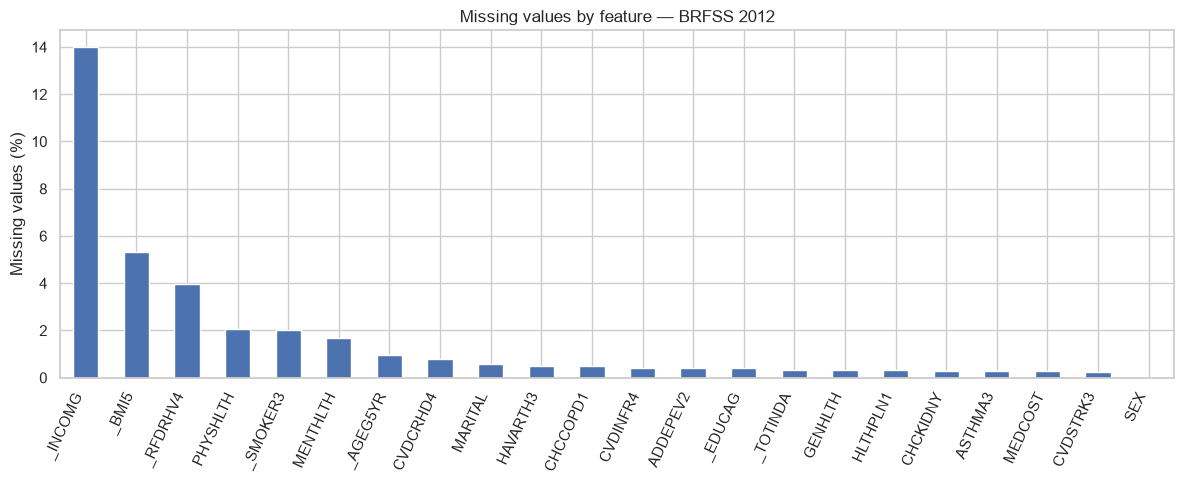

In [8]:
missing = df[features].isna().mean().sort_values(
    ascending=False
)

display(
    (missing * 100)
    .round(2)
    .to_frame("Missing (%)")
)

plt.figure(figsize=(12, 5))
(missing * 100).plot(kind="bar")

plt.title("Missing values by feature — BRFSS 2012")
plt.ylabel("Missing values (%)")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

### 5b — Missing values per respondent

A respondent missing most of the selected features provides
limited information for prediction.

The diagnostic report found only **5 rows** missing more
than 50% of selected features.

**Decision:** Remove these five rows.

In [9]:
row_missing = df[features].isna().mean(axis=1)

display(row_missing.describe())

print(
    "Rows >50% missing:",
    (row_missing > 0.5).sum()
)

before = len(df)

df = df.loc[row_missing <= 0.5].copy()

print("Rows removed:", before - len(df))
print("Remaining shape:", df.shape)

count    474864.000000
mean          0.016214
std           0.034535
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           0.590909
dtype: float64

Rows >50% missing: 5
Rows removed: 5
Remaining shape: (474859, 23)


### Result

After removing the five highly incomplete respondents:

**474,859 rows remain.**

We do not call `dropna()` on the entire dataset because this
would unnecessarily discard respondents with only a few
missing answers.

### 5c — Missingness by target class

We also investigate whether missing answers occur at
different rates across diabetes classes.

In [10]:
missing_by_class = (
    df.groupby("target")[features]
    .apply(lambda g: g.isna().mean())
    .T
)

missing_by_class.columns = [
    "No diabetes",
    "Pre-diabetes",
    "Diabetes"
]

display(
    (missing_by_class * 100).round(2)
)

,No diabetes,Pre-diabetes,Diabetes
_BMI5,5.32,4.20,5.58
GENHLTH,0.30,0.50,0.47
PHYSHLTH,1.83,3.04,3.61
MENTHLTH,1.57,2.37,2.30
CVDSTRK3,0.20,0.80,0.47
CVDINFR4,0.35,0.72,0.79
CVDCRHD4,0.63,1.62,1.77
CHCKIDNY,0.22,0.48,0.70
CHCCOPD1,0.42,0.94,0.82
HAVARTH3,0.48,0.84,0.55


### Remark

According to the diagnostics, income is missing for
approximately:

- **13.86%** of class 0
- **14.82%** of class 1
- **14.83%** of class 2

Physical-health responses also have somewhat different
missing rates between classes.

**Decision:** Impute remaining missing values after splitting.
Missingness indicators may be evaluated later if useful.

## Step 6 — Data types and formats

### Why?

The model needs variables in suitable numerical formats.

In BRFSS, `_BMI5` is stored as BMI multiplied by 100.

For example:

`2850` represents a BMI of `28.50`.

### Decision

Divide `_BMI5` by 100 and rename it `BMI`.

We also distinguish four variable types:

| Type | Examples |
|---|---|
| Numeric | BMI, physical-health days |
| Ordinal | General health, age group, education |
| Binary | Stroke, asthma, physical activity |
| Nominal | Marital status |

In [11]:
df["BMI"] = df["_BMI5"] / 100

df = df.drop(columns="_BMI5")

features = [
    "BMI" if c == "_BMI5" else c
    for c in features
]

numeric_cols = [
    "BMI", "PHYSHLTH", "MENTHLTH"
]

ordinal_cols = [
    "GENHLTH",
    "_AGEG5YR",
    "_EDUCAG",
    "_INCOMG",
    "_SMOKER3"
]

nominal_cols = ["MARITAL"]

binary_cols = [
    c for c in features
    if c not in numeric_cols + ordinal_cols + nominal_cols
]

display(df[numeric_cols].describe())

print("Numeric:", numeric_cols)
print("Ordinal:", ordinal_cols)
print("Binary:", binary_cols)
print("Nominal:", nominal_cols)

,BMI,PHYSHLTH,MENTHLTH
count,449531.000000,465027.000000,466898.000000
mean,27.716019,4.388728,3.510679
std,6.045262,8.909716,7.840085
min,12.020000,0.000000,0.000000
25%,23.630000,0.000000,0.000000
50%,26.630000,0.000000,0.000000
75%,30.670000,3.000000,2.000000
max,98.910000,30.000000,30.000000


Numeric: ['BMI', 'PHYSHLTH', 'MENTHLTH']
Ordinal: ['GENHLTH', '_AGEG5YR', '_EDUCAG', '_INCOMG', '_SMOKER3']
Binary: ['CVDSTRK3', 'CVDINFR4', 'CVDCRHD4', 'CHCKIDNY', 'CHCCOPD1', 'HAVARTH3', 'ADDEPEV2', 'ASTHMA3', '_TOTINDA', '_RFDRHV4', 'HLTHPLN1', 'MEDCOST', 'SEX']
Nominal: ['MARITAL']


### Diagnostic result

Before outlier handling:

| Statistic | BMI |
|---|---:|
| Mean | 27.72 |
| Median | 26.63 |
| Minimum | 12.02 |
| Maximum | 98.91 |

The average and median are different, indicating that BMI
has a right-skewed distribution.

This is a descriptive observation, not a judgment about
individual respondents.

## Step 7 — Outliers and extreme values

### Why?

Some numerical values may be unusually large or small.

We examine outliers using boxplots and the interquartile
range (IQR).

### Diagnostic results

- IQR lower limit: approximately **13.07**
- IQR upper limit: approximately **41.23**
- BMI values outside IQR: **14,436**
- BMI values outside the proposed 12–80 range: **31**

An IQR outlier is not automatically an error.

### Decision

Keep extreme but potentially valid observations.

Following the example's data-quality rule, flag BMI values
outside 12–80 as missing for later imputation.

**Important:** The 12–80 threshold is a project heuristic,
not a universal medical definition of an impossible BMI.

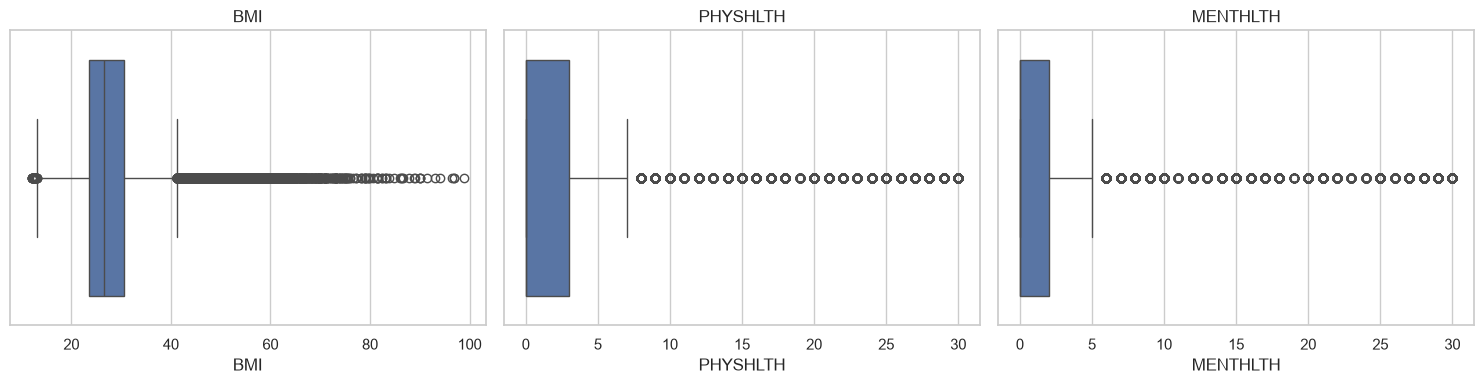

IQR limits: 13.07 41.23
Outside IQR: 14436
BMI outside 12–80: 31


count    449500.000000
mean         27.711925
std           6.025165
min          12.020000
25%          23.630000
50%          26.630000
75%          30.670000
max          79.710000
Name: BMI, dtype: float64

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

q1, q3 = df["BMI"].quantile([0.25, 0.75])
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

print("IQR limits:", round(low, 2), round(high, 2))

print(
    "Outside IQR:",
    ((df["BMI"] < low) | (df["BMI"] > high)).sum()
)

extreme = (df["BMI"] < 12) | (df["BMI"] > 80)

print("BMI outside 12–80:", extreme.sum())

df.loc[extreme, "BMI"] = np.nan

display(df["BMI"].describe())

### Result

After applying the selected quality rule:

- **31 BMI values** are changed to `NaN`.
- Mean BMI is approximately **27.71**.
- The maximum retained BMI is **79.71**.

No respondents are removed in this step.

## Step 8 — Target class imbalance

### Why?

A classifier trained on imbalanced data may favor the
majority class.

For example, predicting class 0 for everyone could achieve
high accuracy without recognizing pre-diabetes or diabetes.

### Diagnostic results

| Target | Respondents | Proportion |
|---|---:|---:|
| 0 — No diabetes | 407,361 | 85.79% |
| 1 — Pre-diabetes | 7,735 | 1.63% |
| 2 — Diabetes | 59,763 | 12.59% |

### Decision

Use:

- Stratified train/test splitting.
- Macro F1 and class-specific recall.
- Class weighting or resampling during modeling, if appropriate.

Any resampling must be applied to training data only.

target
0    407361
1      7735
2     59763
Name: count, dtype: int64

target
0    0.8579
1    0.0163
2    0.1259
Name: proportion, dtype: float64

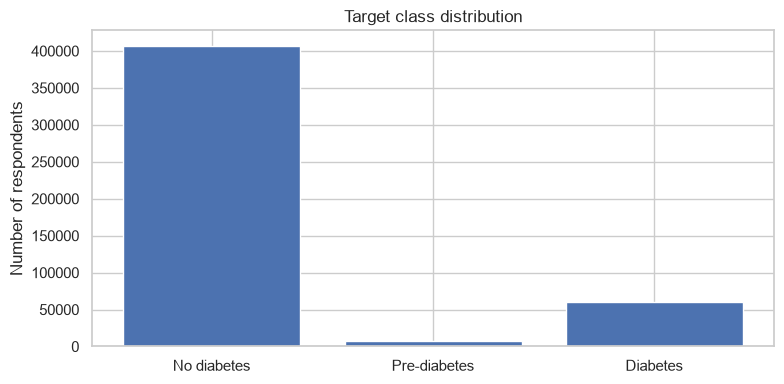

In [13]:
counts = df["target"].value_counts().sort_index()

display(counts)

display(
    df["target"]
    .value_counts(normalize=True)
    .sort_index()
    .round(4)
)

labels = {
    0: "No diabetes",
    1: "Pre-diabetes",
    2: "Diabetes"
}

plt.figure(figsize=(8, 4))

plt.bar(
    [labels[i] for i in counts.index],
    counts.values
)

plt.title("Target class distribution")
plt.ylabel("Number of respondents")
plt.tight_layout()
plt.show()

## Step 9 — Relationships between features and target

### Why?

Before modeling, examine whether the selected variables
show associations with the target.

We also look for unexpectedly strong associations that
might suggest data leakage.

### 9a — Numerical variables by class

Diagnostic means:

| Target | BMI | Physical-health days | Mental-health days |
|---|---:|---:|---:|
| No diabetes | 27.11 | 3.74 | 3.30 |
| Pre-diabetes | 30.19 | 6.59 | 5.01 |
| Diabetes | 31.49 | 8.60 | 4.78 |

These are descriptive group differences. They do not
establish causal relationships.

In [14]:
display(
    df.groupby("target")[numeric_cols]
    .mean()
    .round(2)
)

,BMI,PHYSHLTH,MENTHLTH
target,,,
0,27.11,3.74,3.30
1,30.19,6.59,5.01
2,31.49,8.60,4.78


### 9b — Categorical variables versus target

We calculate the proportion of target classes within each
category of a predictor.

`normalize="index"` means that each category's row sums
to 1 (100%).

In [15]:
for col in ["GENHLTH", "_AGEG5YR", "_INCOMG"]:
    print("\nVariable:", col)

    display(
        pd.crosstab(
            df[col],
            df["target"],
            normalize="index"
        ).round(3)
    )


Variable: GENHLTH


target,0,1,2
GENHLTH,,,
1.0,0.971,0.006,0.022
2.0,0.928,0.012,0.060
3.0,0.835,0.020,0.145
4.0,0.702,0.026,0.272
5.0,0.623,0.026,0.351



Variable: _AGEG5YR


target,0,1,2
_AGEG5YR,,,
1.0,0.983,0.005,0.012
2.0,0.980,0.004,0.016
3.0,0.968,0.006,0.026
4.0,0.953,0.008,0.039
5.0,0.931,0.011,0.058
6.0,0.905,0.014,0.081
7.0,0.872,0.017,0.111
8.0,0.842,0.018,0.140
9.0,0.803,0.020,0.177



Variable: _INCOMG


target,0,1,2
_INCOMG,,,
1.0,0.774,0.023,0.203
2.0,0.808,0.020,0.172
3.0,0.839,0.018,0.143
4.0,0.864,0.016,0.120
5.0,0.910,0.012,0.078


### 9c — Feature associations

The diagnostic report identified the following strongest
absolute Spearman correlations with the numeric target code:

| Feature | Absolute r |
|---|---:|
| General health | 0.284 |
| BMI | 0.233 |
| Age group | 0.210 |
| Arthritis | 0.178 |
| Physical-health days | 0.163 |
| Coronary disease | 0.163 |
| Heart attack | 0.157 |

These associations are useful for exploration.

However, Spearman correlation with a multiclass target coded
0/1/2 is only a rough screening measure. It does not fully
describe predictive usefulness.

GENHLTH     0.284
BMI         0.233
_AGEG5YR    0.210
HAVARTH3    0.178
PHYSHLTH    0.163
CVDCRHD4    0.163
CVDINFR4    0.157
_INCOMG     0.145
_TOTINDA    0.132
CHCKIDNY    0.121
_EDUCAG     0.112
CVDSTRK3    0.111
CHCCOPD1    0.106
ADDEPEV2    0.082
ASTHMA3     0.061
_RFDRHV4    0.055
HLTHPLN1    0.043
MENTHLTH    0.041
_SMOKER3    0.035
MEDCOST     0.018
MARITAL     0.016
SEX         0.011
dtype: float64

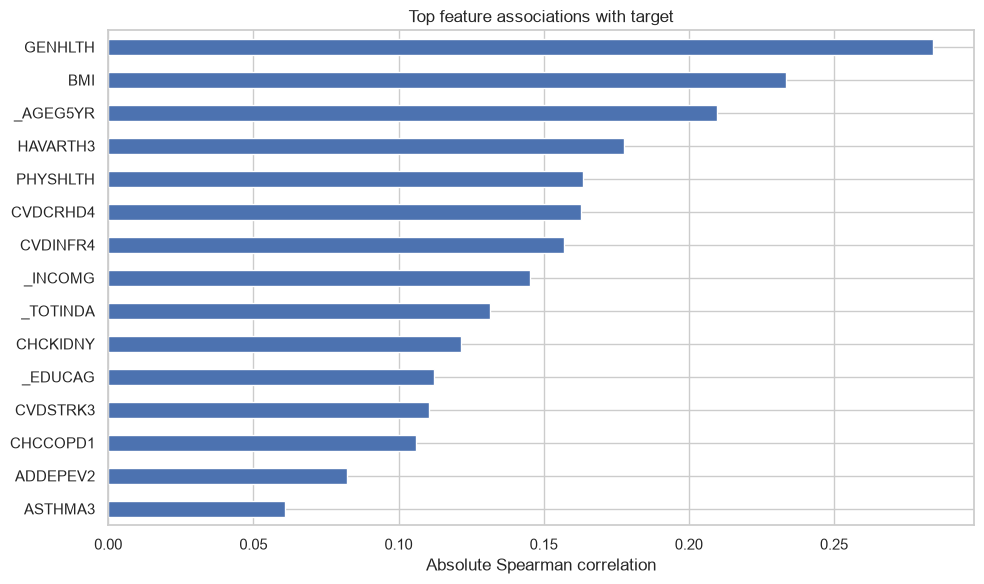

In [16]:
strength = (
    df[features]
    .corrwith(df["target"], method="spearman")
    .abs()
    .sort_values(ascending=False)
)

display(strength.round(3))

plt.figure(figsize=(10, 6))

strength.head(15).sort_values().plot.barh()

plt.title("Top feature associations with target")
plt.xlabel("Absolute Spearman correlation")
plt.tight_layout()
plt.show()

### 9d — Constant and near-constant features

Some medical conditions are uncommon.

The diagnostic report found:

- `CVDSTRK3`: dominant category approximately **95.94%**
- `CHCKIDNY`: dominant category approximately **96.72%**

These variables are not constant.

**Decision:** Keep them, since rare conditions may still
provide useful information.

In [17]:
top_share = pd.Series({
    c: df[c].value_counts(normalize=True).iloc[0]
    for c in features
    if df[c].notna().any()
})

display(
    top_share[top_share > 0.95]
    .sort_values(ascending=False)
)

print(
    "Constant features:",
    df[features].nunique(dropna=True)
    .loc[lambda s: s <= 1]
)

CHCKIDNY    0.967244
CVDSTRK3    0.959400
dtype: float64

Constant features: Series([], dtype: int64)


## Step 10 — Encoding

### Why?

Binary questions often use:

- `1` = Yes
- `2` = No

For machine learning, we prefer:

- `1` = Yes
- `0` = No

However, not every BRFSS variable uses the same direction.

### Coding decisions

- Raw yes/no questions: `1 → 1`, `2 → 0`
- `_TOTINDA`: `1 → 1`, `2 → 0`
- `_RFDRHV4`: `1 → 0`, `2 → 1`
- `SEX`: `1 → 1` (male), `2 → 0` (female)

The computed-variable directions should be confirmed
against the BRFSS 2012 codebook before final use.

Ordinal variables retain their ordered values.

Marital status is one-hot encoded after splitting.

In [18]:
risk_flags = ["_RFDRHV4"]

yes_no_cols = [
    c for c in binary_cols
    if c not in risk_flags + ["SEX"]
]

for col in yes_no_cols:
    df[col] = df[col].map({1: 1, 2: 0})

for col in risk_flags:
    df[col] = df[col].map({1: 0, 2: 1})

df["SEX"] = df["SEX"].map({1: 1, 2: 0})

display(
    df[binary_cols]
    .describe()
    .loc[["min", "max", "mean"]]
)

,CVDSTRK3,CVDINFR4,CVDCRHD4,CHCKIDNY,CHCCOPD1,HAVARTH3,ADDEPEV2,ASTHMA3,_TOTINDA,_RFDRHV4,HLTHPLN1,MEDCOST,SEX
min,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000
max,1.0000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.00000,1.000000
mean,0.0406,0.060728,0.062243,0.032756,0.079831,0.343846,0.184992,0.12806,0.750111,0.053666,0.884493,0.12461,0.402859


### Rename variables

Readable names make the dataset easier to interpret
and use in later modeling steps.

In [19]:
rename = {
    "GENHLTH": "GenHealth",
    "PHYSHLTH": "PhysHealthDays",
    "MENTHLTH": "MentHealthDays",
    "CVDSTRK3": "Stroke",
    "CVDINFR4": "HeartAttack",
    "CVDCRHD4": "CoronaryDisease",
    "CHCKIDNY": "KidneyDisease",
    "CHCCOPD1": "COPD",
    "HAVARTH3": "Arthritis",
    "ADDEPEV2": "Depression",
    "ASTHMA3": "Asthma",
    "_SMOKER3": "Smoker",
    "_TOTINDA": "PhysActivity",
    "_RFDRHV4": "HeavyDrinker",
    "HLTHPLN1": "HealthPlan",
    "MEDCOST": "NoDocBcCost",
    "SEX": "Male",
    "_AGEG5YR": "AgeGroup",
    "_EDUCAG": "Education",
    "_INCOMG": "Income",
    "MARITAL": "Marital"
}

df = df.rename(columns=rename)

numeric_cols = [rename.get(c, c) for c in numeric_cols]
ordinal_cols = [rename.get(c, c) for c in ordinal_cols]
binary_cols = [rename.get(c, c) for c in binary_cols]
nominal_cols = [rename.get(c, c) for c in nominal_cols]
features = [rename.get(c, c) for c in features]

display(df.head())

,GenHealth,PhysHealthDays,MentHealthDays,Stroke,HeartAttack,CoronaryDisease,KidneyDisease,COPD,Arthritis,Depression,Asthma,Smoker,PhysActivity,HeavyDrinker,HealthPlan,NoDocBcCost,Male,AgeGroup,Education,Income,Marital,target,BMI
0,3.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4.0,0.0,0.0,1.0,0.0,1,9.0,3.0,4.0,1.0,0,25.77
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,1.0,0.0,1.0,0.0,1,7.0,4.0,5.0,1.0,0,28.25
2,4.0,2.0,2.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,0.0,NaN,1.0,0.0,0,10.0,4.0,NaN,2.0,0,39.16
3,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,0.0,1.0,0.0,0,11.0,1.0,2.0,1.0,0,24.13
4,4.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4.0,1.0,0.0,1.0,0.0,0,9.0,2.0,NaN,1.0,2,46.00


### Decision

The resulting dataset has:

- Continuous numerical variables
- Ordered categorical variables
- Binary variables encoded as 0/1
- Nominal variables to be one-hot encoded in the pipeline

Remaining missing values are not yet imputed.

## Step 11 — Final checks, save, and split

### 11a — Validate the prepared dataset

### Why?

Assertions help detect preparation mistakes before
using the data for machine learning.

### Expected result

**474,859 rows × 23 columns**

This corresponds to 22 features and one target.

In [20]:
assert df["target"].notna().all()
assert set(df["target"].unique()) == {0, 1, 2}

assert not set(leakage_cols) & set(df.columns)
assert not set(redundant) & set(df.columns)

assert df["BMI"].dropna().between(12, 80).all()

assert df[binary_cols].isin([0, 1, np.nan]).all().all()

assert len(df.select_dtypes(exclude="number").columns) == 0

assert len(features) == 22

print("All validation checks passed.")
print("Final shape:", df.shape)

print(
    "Remaining missing feature cells:",
    df[features].isna().sum().sum()
)

All validation checks passed.
Final shape: (474859, 23)
Remaining missing feature cells: 169354


### 11b — Save the cleaned dataset

### Why?

Saving the prepared data avoids repeating the entire
cleaning process every time we train a model.

The exported dataset contains missing feature values,
because imputation will be learned from training data only.

In [21]:
OUTPUT_CSV = Path("diabetes_clean_2012.csv")

df.to_csv(OUTPUT_CSV, index=False)

print("Saved:", OUTPUT_CSV.resolve())
print("Shape:", df.shape)

Saved: C:\Users\HP\Desktop\ProjetML\diabetes_clean_2012.csv
Shape: (474859, 23)


### 11c — Stratified train/test split

### Why?

We need separate training and testing datasets.

The test dataset must not influence preprocessing statistics.

Use:

- 80% training
- 20% testing
- `stratify=y` to preserve class proportions
- `random_state=42` for reproducibility

In [22]:
from sklearn.model_selection import train_test_split

X = df[features]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

display(
    pd.DataFrame({
        "Train": y_train.value_counts(normalize=True),
        "Test": y_test.value_counts(normalize=True)
    }).sort_index().round(4)
)

Training shape: (379887, 22)
Testing shape: (94972, 22)


,Train,Test
target,,
0,0.8579,0.8579
1,0.0163,0.0163
2,0.1259,0.1259


### 11d — Preprocessing pipeline

### Why?

The remaining missing values need to be imputed.

Some models also require feature scaling.

We use:

| Feature type | Transformation |
|---|---|
| Numeric | Median imputation + StandardScaler |
| Ordinal | Most-frequent imputation |
| Binary | Most-frequent imputation |
| Nominal | Most-frequent imputation + OneHotEncoder |

### Data leakage prevention

- `fit_transform(X_train)` learns and applies preprocessing.
- `transform(X_test)` only applies the learned transformations.

The test data does not determine imputation values,
scaling statistics, or encoded categories.

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocess = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]),
        numeric_cols
    ),
    (
        "ord",
        SimpleImputer(strategy="most_frequent"),
        ordinal_cols
    ),
    (
        "bin",
        SimpleImputer(strategy="most_frequent"),
        binary_cols
    ),
    (
        "nom",
        Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        nominal_cols
    )
])

X_train_prep = preprocess.fit_transform(X_train)
X_test_prep = preprocess.transform(X_test)

print("Prepared training shape:", X_train_prep.shape)
print("Prepared testing shape:", X_test_prep.shape)

print(
    "Missing values in train:",
    np.isnan(X_train_prep).sum()
)

print(
    "Missing values in test:",
    np.isnan(X_test_prep).sum()
)

Prepared training shape: (379887, 27)
Prepared testing shape: (94972, 27)
Missing values in train: 0
Missing values in test: 0


### Result / Decision

The preprocessing pipeline should produce feature matrices
without missing values.

The preprocessor has been fitted on training data only.

**For future cross-validation**, place this preprocessing
inside the same scikit-learn `Pipeline` as the classifier,
so each validation fold learns its own preprocessing parameters.

## Summary — Data Preparation BRFSS 2012

| Step | Diagnostic finding | Decision |
|---|---|---|
| 0 — Load | 475,687 × 359 | Preserve original data |
| 1 — Target | 823 invalid targets | Keep 474,864 respondents |
| 2 — Selection | 27 candidate features | Exclude administrative and leakage fields |
| 4 — Special codes | Hidden missing codes | Decode column by column |
| 3 — Redundancy | Five strongly related pairs | Keep 22 predictors |
| 5 — Missing data | Income 14%, BMI 5.33% | Remove 5 highly incomplete rows |
| 6 — Formats | BMI stored ×100 | Convert to usual BMI units |
| 7 — Outliers | 31 BMI values outside 12–80 | Flag as missing |
| 8 — Balance | Class 1 approximately 1.63% | Stratified split |
| 9 — Associations | Health, BMI, age strongest | Retain selected predictors |
| 10 — Encoding | Mixed category codes | Binary 0/1; nominal one-hot |
| 11 — Final | 474,859 × 23 | Export, split, preprocess |

### Final dataset

**474,859 respondents**

**22 predictor variables**

**1 target variable**

### Files

- Input: `2012.csv`
- Output: `diabetes_clean_2012.csv`
- Notebook: `BRFSS_2012_Data_Preparation.ipynb`

### Next step — Modeling

The prepared data can be used to train and compare
classification algorithms such as:

- Logistic Regression
- Random Forest
- Gradient Boosting

Because the target is imbalanced, evaluate with:

- Confusion matrix
- Precision
- Recall
- Macro F1-score
- Class-specific performance

### Methodological limitations

The original BRFSS survey uses a complex sampling design.
Unweighted respondent percentages should not be interpreted
as population prevalence estimates.

The pregnancy-only target mapping, BMI quality threshold,
and survey-code mappings should be documented and validated
before treating this as a final scientific dataset.